# 01 - Exploration du dataset PlantVillage

Objectif de ce notebook : comprendre le dataset avant d'entraîner quoi que ce soit.

On regarde :
1. La structure des dossiers et le nombre de classes
2. Le nombre d'images par classe (équilibre / déséquilibre)
3. Un aperçu visuel de quelques images par classe
4. Les dimensions et formats des images
5. La détection d'images corrompues ou illisibles

> Prérequis : le dossier `PlantVillage/` doit être à la racine du repo, avec un sous-dossier par classe (ex: `PlantVillage/Tomato___Early_blight/`, `PlantVillage/Tomato___healthy/`, etc.)


In [11]:
import os
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# Chemin vers le dataset (à adapter si besoin)
DATA_DIR = Path("../Plant_sickness/PlantVillage")  # depuis notebooks/, on remonte d'un cran

assert DATA_DIR.exists(), f"Dossier introuvable : {DATA_DIR.resolve()}"
print(f"Dataset trouvé : {DATA_DIR.resolve()}")

Dataset trouvé : C:\Users\clement\Documents\GitHub\Plant_sickness\PlantVillage


## 1. Structure des dossiers et classes

In [12]:
classes = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
print(f"Nombre de classes : {len(classes)}\n")
for c in classes:
    print(" -", c)

Nombre de classes : 15

 - Pepper__bell___Bacterial_spot
 - Pepper__bell___healthy
 - Potato___Early_blight
 - Potato___Late_blight
 - Potato___healthy
 - Tomato_Bacterial_spot
 - Tomato_Early_blight
 - Tomato_Late_blight
 - Tomato_Leaf_Mold
 - Tomato_Septoria_leaf_spot
 - Tomato_Spider_mites_Two_spotted_spider_mite
 - Tomato__Target_Spot
 - Tomato__Tomato_YellowLeaf__Curl_Virus
 - Tomato__Tomato_mosaic_virus
 - Tomato_healthy


## 2. Nombre d'images par classe

C'est l'étape la plus importante avant d'entraîner un modèle : si le dataset est très déséquilibré
(une classe avec 2000 images, une autre avec 100), il faudra en tenir compte (pondération de la loss,
augmentation ciblée, ou sous-échantillonnage).

In [13]:
extensions = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

counts = {}
for c in classes:
    class_dir = DATA_DIR / c
    n = sum(1 for f in class_dir.iterdir() if f.suffix in extensions)
    counts[c] = n

df_counts = pd.DataFrame(list(counts.items()), columns=["classe", "n_images"]).sort_values("n_images", ascending=False)
df_counts

,classe,n_images
12,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
5,Tomato_Bacterial_spot,2127
7,Tomato_Late_blight,1909
9,Tomato_Septoria_leaf_spot,1771
10,Tomato_Spider_mites_Two_spotted_spider_mite,1676
14,Tomato_healthy,1591
1,Pepper__bell___healthy,1478
11,Tomato__Target_Spot,1404
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000


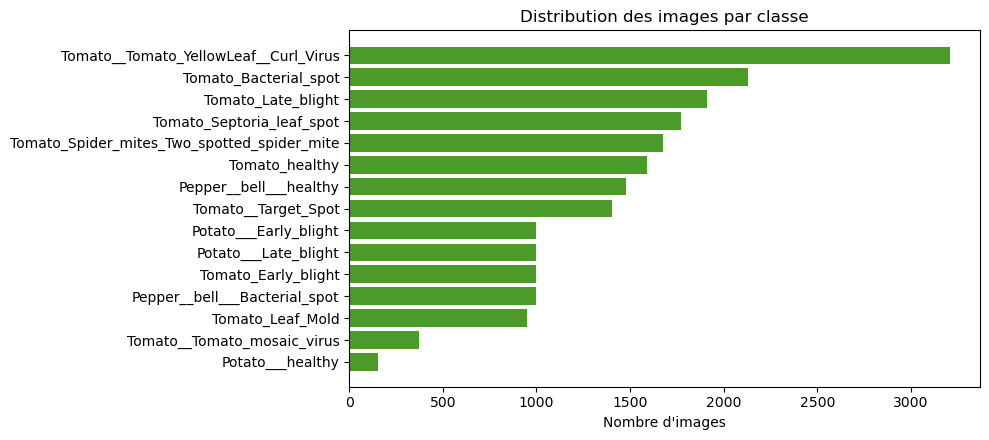


Total images : 20638
Classe la plus représentée  : Tomato__Tomato_YellowLeaf__Curl_Virus (3208 images)
Classe la moins représentée : Potato___healthy (152 images)
Ratio déséquilibre (max/min) : 21.1x


In [14]:
fig, ax = plt.subplots(figsize=(10, max(4, len(classes) * 0.3)))
ax.barh(df_counts["classe"], df_counts["n_images"], color="#4C9A2A")
ax.set_xlabel("Nombre d'images")
ax.set_title("Distribution des images par classe")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(f"\nTotal images : {df_counts['n_images'].sum()}")
print(f"Classe la plus représentée  : {df_counts.iloc[0]['classe']} ({df_counts.iloc[0]['n_images']} images)")
print(f"Classe la moins représentée : {df_counts.iloc[-1]['classe']} ({df_counts.iloc[-1]['n_images']} images)")
ratio = df_counts.iloc[0]['n_images'] / df_counts.iloc[-1]['n_images']
print(f"Ratio déséquilibre (max/min) : {ratio:.1f}x")

## 3. Aperçu visuel

On affiche quelques exemples par classe pour se faire une idée à l'œil des différences
(taches, couleurs, textures des maladies vs feuilles saines).

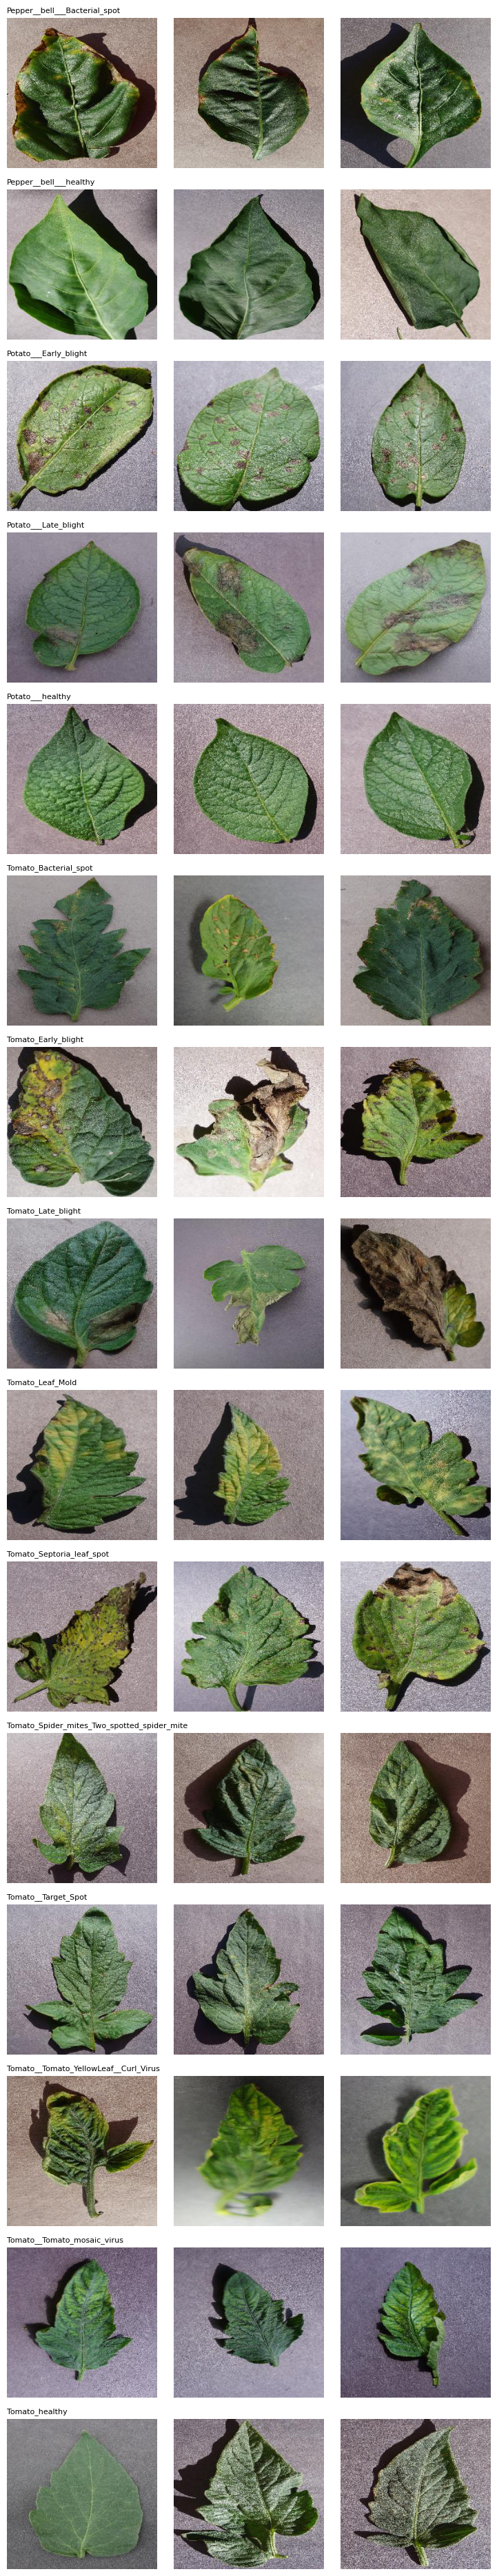

In [15]:
import random

n_per_class = 3
sample_classes = classes  # ou classes[:8] si tu as beaucoup de classes et veux limiter l'affichage

fig, axes = plt.subplots(len(sample_classes), n_per_class, figsize=(n_per_class * 2.5, len(sample_classes) * 2.5))
if len(sample_classes) == 1:
    axes = [axes]

for i, c in enumerate(sample_classes):
    class_dir = DATA_DIR / c
    files = [f for f in class_dir.iterdir() if f.suffix in extensions]
    sample_files = random.sample(files, min(n_per_class, len(files)))
    for j in range(n_per_class):
        ax = axes[i][j] if len(sample_classes) > 1 else axes[j]
        if j < len(sample_files):
            img = Image.open(sample_files[j])
            ax.imshow(img)
        ax.axis("off")
        if j == 0:
            ax.set_ylabel(c, fontsize=8)
    axes[i][0].set_title(c, fontsize=8, loc="left") if len(sample_classes) > 1 else None

plt.tight_layout()
plt.show()

## 4. Dimensions et formats des images

Utile pour décider de la taille de redimensionnement (resize) à utiliser à l'entraînement,
et vérifier qu'il n'y a pas de format exotique (CMYK, RGBA, etc.) qui casserait le pipeline.

In [16]:
import itertools

sample_size = 300  # on échantillonne pour aller vite plutôt que de tout scanner
all_files = []
for c in classes:
    class_dir = DATA_DIR / c
    all_files.extend([f for f in class_dir.iterdir() if f.suffix in extensions])

sample_files = random.sample(all_files, min(sample_size, len(all_files)))

sizes = []
modes = []
for f in sample_files:
    try:
        with Image.open(f) as img:
            sizes.append(img.size)  # (width, height)
            modes.append(img.mode)
    except Exception as e:
        print(f"Erreur lecture {f}: {e}")

widths, heights = zip(*sizes)
print(f"Échantillon analysé : {len(sizes)} images")
print(f"Largeur  - min: {min(widths)}, max: {max(widths)}, moyenne: {sum(widths)/len(widths):.0f}")
print(f"Hauteur  - min: {min(heights)}, max: {max(heights)}, moyenne: {sum(heights)/len(heights):.0f}")
print(f"\nModes de couleur rencontrés : {Counter(modes)}")

Échantillon analysé : 300 images
Largeur  - min: 256, max: 256, moyenne: 256
Hauteur  - min: 256, max: 256, moyenne: 256

Modes de couleur rencontrés : Counter({'RGB': 300})


In [17]:
unique_sizes = Counter(sizes)
print(f"Nombre de dimensions différentes : {len(unique_sizes)}")
print("Les 5 plus fréquentes :")
for size, n in unique_sizes.most_common(5):
    print(f"  {size} -> {n} images")

Nombre de dimensions différentes : 1
Les 5 plus fréquentes :
  (256, 256) -> 300 images


## 5. Détection d'images corrompues ou illisibles

On scanne tout le dataset (ça peut prendre quelques minutes selon le volume) pour repérer
les fichiers qui ne s'ouvrent pas correctement — mieux vaut le savoir maintenant plutôt que
de planter un entraînement au bout de 2h.

In [18]:
corrupted = []

for c in classes:
    class_dir = DATA_DIR / c
    for f in class_dir.iterdir():
        if f.suffix not in extensions:
            continue
        try:
            with Image.open(f) as img:
                img.verify()
        except Exception as e:
            corrupted.append((str(f), str(e)))

print(f"Images corrompues trouvées : {len(corrupted)}")
for path, err in corrupted[:20]:
    print(f"  - {path} : {err}")

Images corrompues trouvées : 0


## Résumé et prochaines étapes

À compléter après exécution avec tes observations, par exemple :
- Nombre total de classes / images
- Niveau de déséquilibre entre classes → décider si on pondère la loss ou si on sous-échantillonne
- Taille de resize à utiliser pour l'entraînement (ex: 224x224, standard pour transfer learning)
- Images corrompues à exclure du pipeline

**Prochaine étape : notebook `02_training.ipynb`** — transfer learning avec PyTorch (ResNet18/MobileNet via `timm`).